<a href="https://colab.research.google.com/github/Sneha-Rani-M/4IK25CS200_DAV_LAB/blob/main/4IK25CS200_EXP_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EXP 11- Hierarchial Clustering


In [ ]:
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

Load dataset and select feature

In [ ]:
df = pd.read_csv('/content/House_Price_dataset.csv')
df = df[df['purpose'] == 'For Sale']
df = df[['price', 'bedrooms', 'baths', 'Area Size']].dropna()

Clean data:remove zero values and extreme outliers

In [ ]:
df = df[(df['bedrooms'] > 0) & (df['baths'] > 0)]
df = df[df['price'] < df['price'].quantile(0.99)]
df = df[df['Area Size'] < df['Area Size'].quantile(0.99)]

Take a small sample (dataset is very large, dendrogram needs few rows)

In [ ]:
df = df.sample(n=100, random_state=42).reset_index(drop=True)

Scale the features

In [ ]:
X = df[['price', 'bedrooms', 'baths', 'Area Size']]
X_scaled = StandardScaler().fit_transform(X)


Build and plot the dendrogram

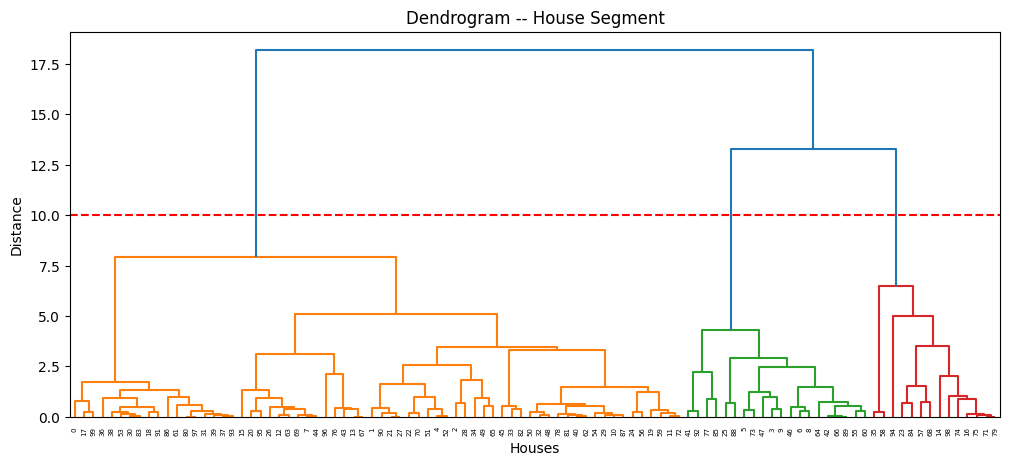

In [ ]:
linked = linkage(X_scaled, method='ward')
plt.figure(figsize=(12, 5))
dendrogram(linked)
plt.title('Dendrogram -- House Segment')
plt.xlabel('Houses');plt.ylabel('Distance')
plt.axhline(y=10, color='red', linestyle='--')
plt.show()

Fit Agglomerative Clustering using the chosen cut

In [ ]:
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
df['HC_Cluster']=hc.fit_predict(X_scaled)

Clustered Summary

In [ ]:
print(df['HC_Cluster'].value_counts())
print(df.groupby('HC_Cluster').mean().round(2))

HC_Cluster
0    66
2    20
1    14
Name: count, dtype: int64
                  price  bedrooms  baths  Area Size
HC_Cluster                                         
0           11235909.09      2.94   2.92       5.07
1           60335714.29      5.64   6.14       1.24
2           26460000.00      4.75   5.25      10.45


Plot the clusters

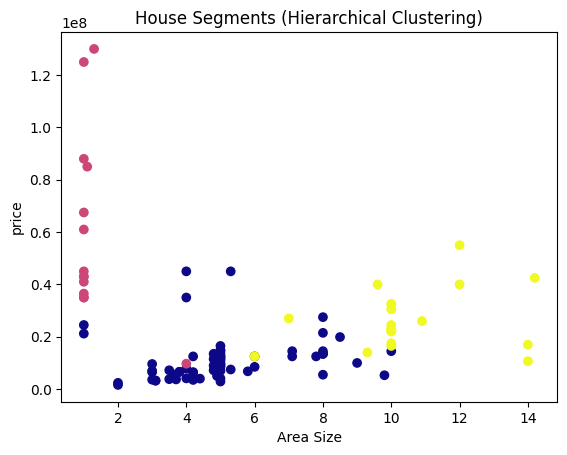

In [ ]:
plt.scatter(df['Area Size'], df['price'], c=df['HC_Cluster'], cmap='plasma')
plt.xlabel('Area Size');plt.ylabel('price')
plt.title('House Segments (Hierarchical Clustering)');
plt.show()